## SL MINI PROJECT
## Personal Wellbeing and Productivity Analyzer – ML-Based Productivity Prediction


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
url = "/content/digital_lifestyle_benchmark_2025.csv"
df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Number of rows: 3500
Number of columns: 24


,id,age,gender,region,income_level,education_level,daily_role,device_hours_per_day,phone_unlocks,notifications_per_day,...,sleep_quality,anxiety_score,depression_score,stress_level,happiness_score,focus_score,high_risk_flag,device_type,productivity_score,digital_dependence_score
0,1,40,Female,Asia,High,High School,Part-time/Shift,3.54,45,561,...,3.353627,9.926651,5.0,6.593289,8.0,23.0,0,Android,70.000000,25.700000
1,2,27,Male,Africa,Lower-Mid,Master,Full-time Employee,5.65,100,393,...,2.908147,4.000000,4.0,4.126926,8.1,35.0,0,Laptop,64.000000,30.100000
2,3,31,Male,North America,Lower-Mid,Bachelor,Full-time Employee,8.87,181,231,...,2.889213,4.000000,8.0,1.429139,7.6,15.0,0,Android,65.299301,40.600000
3,4,41,Female,Middle East,Low,Master,Caregiver/Home,4.05,94,268,...,3.097488,7.093357,9.0,4.995512,7.8,28.0,1,Tablet,80.000000,36.684152
4,5,26,Female,Europe,Lower-Mid,Bachelor,Full-time Employee,13.07,199,91,...,2.786098,7.028125,15.0,9.448757,4.2,70.0,1,Android,65.299301,48.400000


In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Column names:
['id', 'age', 'gender', 'region', 'income_level', 'education_level', 'daily_role', 'device_hours_per_day', 'phone_unlocks', 'notifications_per_day', 'social_media_mins', 'study_mins', 'physical_activity_days', 'sleep_hours', 'sleep_quality', 'anxiety_score', 'depression_score', 'stress_level', 'happiness_score', 'focus_score', 'high_risk_flag', 'device_type', 'productivity_score', 'digital_dependence_score']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        3500 non-null   int64  
 1   age                       3500 non-null   int64  
 2   gender                    3500 non-null   object 
 3   region                    3500 non-null   object 
 4   income_level              3500 non-null   object 
 5   education_level           3500 non-null   object 
 6   

In [6]:
print("Dataset shape:", df.shape)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nColumn data types:")
print(df.dtypes)

print("\nUnique values in each column:")
print(df.nunique())


Dataset shape: (3500, 24)

Duplicate rows: 0

Missing values in each column:
id                          0
age                         0
gender                      0
region                      0
income_level                0
education_level             0
daily_role                  0
device_hours_per_day        0
phone_unlocks               0
notifications_per_day       0
social_media_mins           0
study_mins                  0
physical_activity_days      0
sleep_hours                 0
sleep_quality               0
anxiety_score               0
depression_score            0
stress_level                0
happiness_score             0
focus_score                 0
high_risk_flag              0
device_type                 0
productivity_score          0
digital_dependence_score    0
dtype: int64

Column data types:
id                            int64
age                           int64
gender                       object
region                       object
income_level              

In [7]:

# Clean the dataset
df_clean = df.copy()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Fill missing numeric values with their column median
numeric_columns = df_clean.select_dtypes(
    include="number"
).columns

for column in numeric_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

# Fill missing text/category values with the most frequent value
categorical_columns = df_clean.select_dtypes(
    include=["object", "category", "string"]
).columns

for column in categorical_columns:
    if df_clean[column].notna().any():
        df_clean[column] = df_clean[column].fillna(
            df_clean[column].mode()[0]
        )

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum().sum())

print("\nRemaining duplicate rows:")
print(df_clean.duplicated().sum())


Original dataset shape: (3500, 24)
Cleaned dataset shape: (3500, 24)

Remaining missing values:
0

Remaining duplicate rows:
0


In [8]:

# Step 3C: Validate key columns

important_columns = [
    "age",
    "sleep_hours",
    "sleep_quality",
    "physical_activity_days",
    "anxiety_score",
    "depression_score",
    "stress_level",
    "focus_score",
    "happiness_score",
    "productivity_score",
    "study_mins"
]

for column in important_columns:
    if column in df_clean.columns:
        print(f"\n{column}")
        print("Minimum:", df_clean[column].min())
        print("Maximum:", df_clean[column].max())
    else:
        print(f"\nColumn not found: {column}")



age
Minimum: 13
Maximum: 50

sleep_hours
Minimum: 3.0
Maximum: 11.00456608768657

sleep_quality
Minimum: 1.0
Maximum: 5.0

physical_activity_days
Minimum: 0.0
Maximum: 7.0

anxiety_score
Minimum: 0.0
Maximum: 27.154216664249446

depression_score
Minimum: 0.0
Maximum: 27.0

stress_level
Minimum: 1.0
Maximum: 10.0

focus_score
Minimum: 0.0
Maximum: 100.0

happiness_score
Minimum: 0.0
Maximum: 10.0

productivity_score
Minimum: 33.0
Maximum: 95.0

study_mins
Minimum: 0
Maximum: 418


In [9]:

# Step 5.1: Overall Dataset Summary

print("=" * 55)
print(" OVERALL WELLBEING AND PRODUCTIVITY ANALYSIS")
print("=" * 55)

print("\nTOTAL RECORDS ANALYZED:", len(df_clean))

print("\nAVERAGE INDICATOR VALUES")
print("-" * 35)

summary_columns = [
    "sleep_hours",
    "sleep_quality",
    "physical_activity_days",
    "anxiety_score",
    "depression_score",
    "stress_level",
    "happiness_score",
    "focus_score",
    "productivity_score",
    "device_hours_per_day",
    "digital_dependence_score"
]

display(
    df_clean[summary_columns]
    .mean()
    .round(2)
    .rename("Dataset Average")
    .to_frame()
)

print("\nMEDIAN INDICATOR VALUES")
print("-" * 35)

display(
    df_clean[summary_columns]
    .median()
    .round(2)
    .rename("Dataset Median")
    .to_frame()
)

print("\nRECORDS BY DAILY ROLE")
print("-" * 35)

display(df_clean["daily_role"].value_counts().to_frame("Count"))


 OVERALL WELLBEING AND PRODUCTIVITY ANALYSIS

TOTAL RECORDS ANALYZED: 3500

AVERAGE INDICATOR VALUES
-----------------------------------


,Dataset Average
sleep_hours,7.25
sleep_quality,2.71
physical_activity_days,3.35
anxiety_score,7.18
depression_score,8.83
stress_level,5.08
happiness_score,6.42
focus_score,41.60
productivity_score,65.30
device_hours_per_day,7.32



MEDIAN INDICATOR VALUES
-----------------------------------


,Dataset Median
sleep_hours,7.29
sleep_quality,2.91
physical_activity_days,3.00
anxiety_score,6.00
depression_score,8.00
stress_level,4.81
happiness_score,7.50
focus_score,44.00
productivity_score,65.30
device_hours_per_day,6.76



RECORDS BY DAILY ROLE
-----------------------------------


,Count
daily_role,
Full-time Employee,1429
Student,905
Part-time/Shift,659
Unemployed_Looking,358
Caregiver/Home,149


In [10]:

# Step 4: Individual Wellbeing and Productivity Analyzer

def generate_report(person_id):

    # Find the selected person
    person = df_clean[df_clean["id"] == person_id]

    # Check whether the ID exists
    if person.empty:
        print("No person found with ID:", person_id)
        return

    # Get the person's record
    person = person.iloc[0]

    print("=" * 55)
    print(" PERSONAL WELLBEING AND PRODUCTIVITY REPORT")
    print("=" * 55)

    print("\nPERSONAL DETAILS")
    print("-" * 30)
    print("ID:", person["id"])
    print("Age:", person["age"])
    print("Daily role:", person["daily_role"])

    print("\nPHYSICAL WELLBEING")
    print("-" * 30)
    print("Sleep hours:", round(person["sleep_hours"], 2))
    print("Sleep quality (1-5):", round(person["sleep_quality"], 2))
    print("Physical activity days per week:",
          round(person["physical_activity_days"], 2))

    print("\nMENTAL WELLBEING INDICATORS")
    print("-" * 30)
    print("Anxiety score:", round(person["anxiety_score"], 2))
    print("Depression score:", round(person["depression_score"], 2))
    print("Stress level (1-10):", round(person["stress_level"], 2))

    print("\nEMOTIONAL WELLBEING INDICATORS")
    print("-" * 30)
    print("Happiness score (0-10):",
          round(person["happiness_score"], 2))

    print("\nPRODUCTIVITY")
    print("-" * 30)
    print("Focus score (0-100):", round(person["focus_score"], 2))
    print("Productivity score:",
          round(person["productivity_score"], 2))
    print("Study time (minutes):", person["study_mins"])

    print("\nDIGITAL HABITS")
    print("-" * 30)
    print("Daily device hours:",
          round(person["device_hours_per_day"], 2))
    print("Phone unlocks:", person["phone_unlocks"])
    print("Daily social media minutes:", person["social_media_mins"])
    print("Digital dependence score:",
          round(person["digital_dependence_score"], 2))

    print("\nOBSERVATIONS")
    print("-" * 30)

    # Compare the person's values with the dataset median
    comparisons = {
        "sleep_hours": ("Sleep duration", "higher"),
        "sleep_quality": ("Sleep quality", "higher"),
        "physical_activity_days": ("Physical activity", "higher"),
        "happiness_score": ("Happiness score", "higher"),
        "focus_score": ("Focus score", "higher"),
        "productivity_score": ("Productivity score", "higher"),
        "anxiety_score": ("Anxiety score", "lower"),
        "depression_score": ("Depression score", "lower"),
        "stress_level": ("Stress level", "lower")
    }

    for column, (label, preferred_direction) in comparisons.items():

        dataset_median = df_clean[column].median()
        value = person[column]

        if value == dataset_median:
            observation = "equal to"
        elif preferred_direction == "higher":
            observation = (
                "above" if value > dataset_median else "below"
            )
        else:
            observation = (
                "below" if value < dataset_median else "above"
            )

        print(
            f"{label}: {observation} the dataset median "
            f"({dataset_median:.2f})."
        )

    print("\nNOTE")
    print("-" * 30)
    print(
        "These observations compare one record with this dataset. "
        "They are not medical diagnoses or definitive assessments "
        "of a person's wellbeing."
    )

    print("=" * 55)


In [11]:


person_id = int(input("Enter a person ID (1-3500): "))

generate_report(person_id)


Enter a person ID (1-3500): 34
 PERSONAL WELLBEING AND PRODUCTIVITY REPORT

PERSONAL DETAILS
------------------------------
ID: 34
Age: 45
Daily role: Part-time/Shift

PHYSICAL WELLBEING
------------------------------
Sleep hours: 9.23
Sleep quality (1-5): 2.86
Physical activity days per week: 1.0

MENTAL WELLBEING INDICATORS
------------------------------
Anxiety score: 4.0
Depression score: 1.0
Stress level (1-10): 1.0

EMOTIONAL WELLBEING INDICATORS
------------------------------
Happiness score (0-10): 2.0

PRODUCTIVITY
------------------------------
Focus score (0-100): 86.0
Productivity score: 54.0
Study time (minutes): 118

DIGITAL HABITS
------------------------------
Daily device hours: 0.98
Phone unlocks: 19
Daily social media minutes: 3
Digital dependence score: 6.2

OBSERVATIONS
------------------------------
Sleep duration: above the dataset median (7.29).
Sleep quality: below the dataset median (2.91).
Physical activity: below the dataset median (3.00).
Happiness score: b

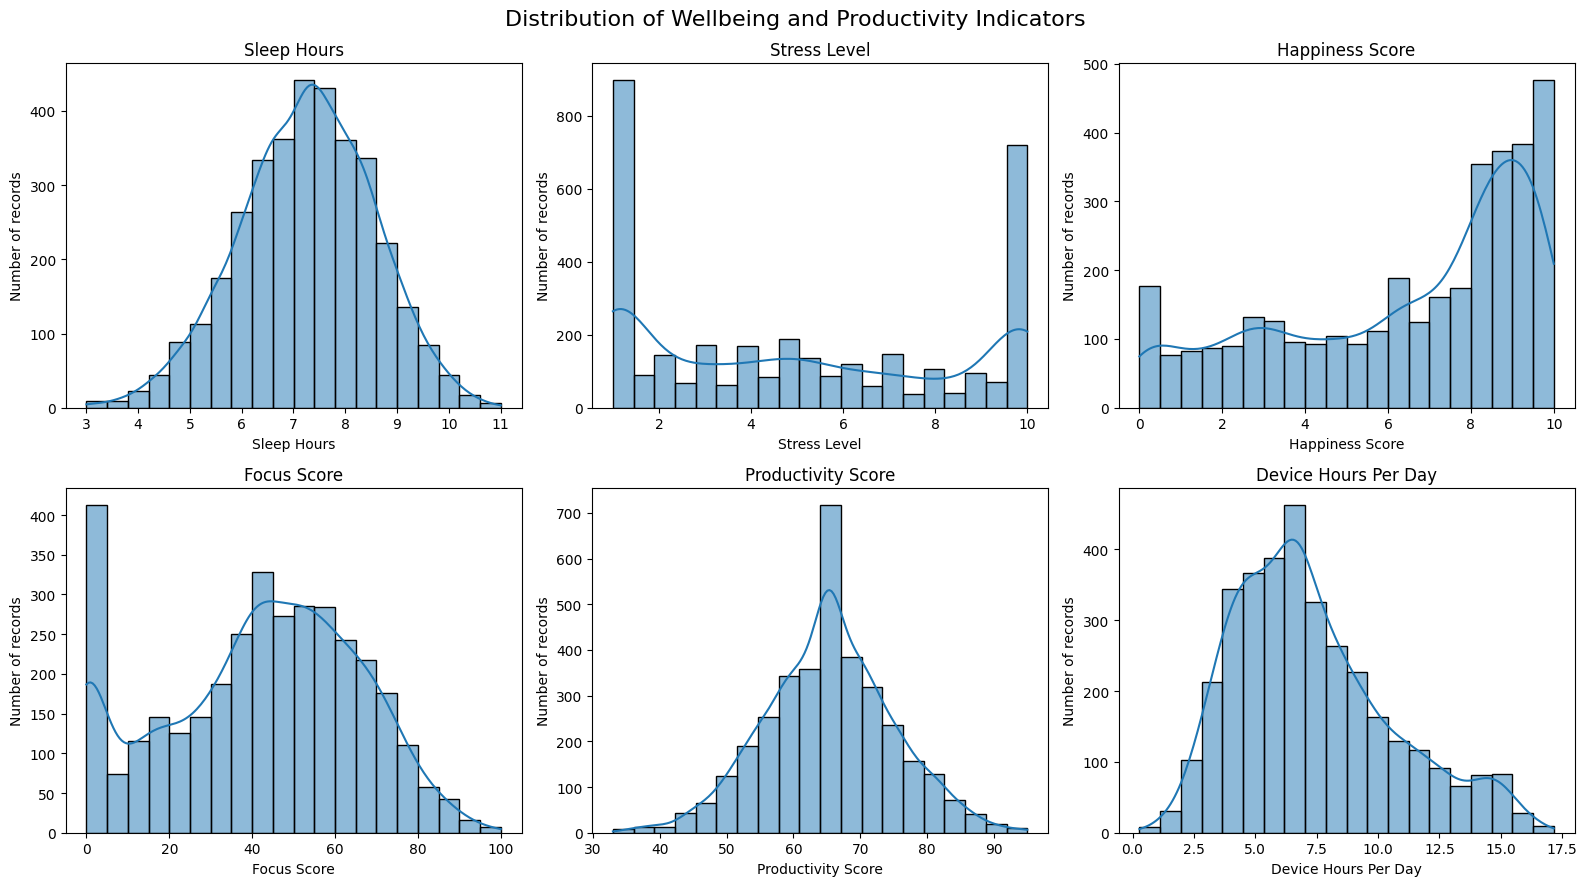

In [12]:

# Step 5.2: Visualize key indicators

plot_columns = [
    "sleep_hours",
    "stress_level",
    "happiness_score",
    "focus_score",
    "productivity_score",
    "device_hours_per_day"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, column in zip(axes.flat, plot_columns):
    sns.histplot(
        data=df_clean,
        x=column,
        bins=20,
        kde=True,
        ax=ax
    )
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Number of records")

plt.suptitle(
    "Distribution of Wellbeing and Productivity Indicators",
    fontsize=16
)
plt.tight_layout()
plt.show()


In [13]:
|
# Step 6: Automatic Insight Generation

print("=" * 60)
print(" AUTOMATIC DATASET INSIGHTS")
print("=" * 60)

# 1. Find indicators associated with productivity

if "productivity_score" in df_clean.columns:

    numeric_data = df_clean.select_dtypes(include="number")

    correlations = numeric_data.corr()["productivity_score"]

    # Remove productivity's correlation with itself
    correlations = correlations.drop(
        labels=["productivity_score"],
        errors="ignore"
    )

    # Keep only valid correlation values
    correlations = correlations.dropna()

    # Display the strongest relationships
    strongest = correlations.reindex(
        correlations.abs().sort_values(ascending=False).index
    ).head(5)

    print("\n1. INDICATORS MOST ASSOCIATED WITH PRODUCTIVITY")
    print("-" * 50)

    if strongest.empty:
        print("Not enough valid data to calculate correlations.")
    else:
        for indicator, value in strongest.items():
            direction = (
                "positive" if value > 0
                else "negative" if value < 0
                else "no linear"
            )

            print(
                f"{indicator}: correlation = {value:.2f} "
                f"({direction} relationship)"
            )

else:
    print("Productivity score column was not found.")


# 2. Compare average productivity across daily roles

if all(
    column in df_clean.columns
    for column in ["daily_role", "productivity_score"]
):

    role_productivity = (
        df_clean.groupby("daily_role")["productivity_score"]
        .mean()
        .sort_values(ascending=False)
    )

    print("\n2. AVERAGE PRODUCTIVITY BY DAILY ROLE")
    print("-" * 50)

    print(role_productivity.round(2).to_string())

    if not role_productivity.empty:
        print(
            "\nRole with the highest average productivity:",
            role_productivity.index[0]
        )
        print(
            "Average productivity:",
            round(role_productivity.iloc[0], 2)
        )

else:
    print("\nDaily role or productivity column was not found.")


# 3. Compare digital habits with dataset medians

digital_columns = [
    "device_hours_per_day",
    "social_media_mins",
    "phone_unlocks",
    "digital_dependence_score"
]

available_digital_columns = [
    column for column in digital_columns
    if column in df_clean.columns
]

print("\n3. DIGITAL HABIT SUMMARY")
print("-" * 50)

for column in available_digital_columns:

    average = df_clean[column].mean()
    median = df_clean[column].median()

    print(f"\n{column}")
    print(f"Dataset average: {average:.2f}")
    print(f"Dataset median: {median:.2f}")

    if average > median:
        print("The average is above the median.")
    elif average < median:
        print("The average is below the median.")
    else:
        print("The average equals the median.")

if not available_digital_columns:
    print("No expected digital habit columns were found.")


# 4. General dataset observations

print("\n4. GENERAL OBSERVATIONS")
print("-" * 50)

for column in [
    "sleep_hours",
    "stress_level",
    "happiness_score",
    "focus_score",
    "productivity_score"
]:
    if column in df_clean.columns:
        print(
            f"Average {column}: "
            f"{df_clean[column].mean():.2f}"
        )

print("\nInterpretation note:")
print(
    "These findings describe patterns in the dataset. "
    "Correlations do not establish cause and effect, "
    "and group averages do not describe every individual."
)


 AUTOMATIC DATASET INSIGHTS

1. INDICATORS MOST ASSOCIATED WITH PRODUCTIVITY
--------------------------------------------------
device_hours_per_day: correlation = 0.09 (positive relationship)
phone_unlocks: correlation = 0.05 (positive relationship)
digital_dependence_score: correlation = 0.04 (positive relationship)
sleep_hours: correlation = -0.03 (negative relationship)
stress_level: correlation = 0.03 (positive relationship)

2. AVERAGE PRODUCTIVITY BY DAILY ROLE
--------------------------------------------------
daily_role
Caregiver/Home        65.58
Unemployed_Looking    65.57
Full-time Employee    65.44
Student               65.16
Part-time/Shift       64.99

Role with the highest average productivity: Caregiver/Home
Average productivity: 65.58

3. DIGITAL HABIT SUMMARY
--------------------------------------------------

device_hours_per_day
Dataset average: 7.32
Dataset median: 6.76
The average is above the median.

social_media_mins
Dataset average: 159.36
Dataset median: 119

In [14]:

# STEP 7: PERSONALIZED HABIT RECOMMENDATION SYSTEM

def generate_habit_recommendations(person):

    recommendations = []

    # Compare a person's value with the dataset median
    def below_median(column):
        return (
            column in df_clean.columns
            and pd.notna(person.get(column))
            and person[column] < df_clean[column].median()
        )

    def above_median(column):
        return (
            column in df_clean.columns
            and pd.notna(person.get(column))
            and person[column] > df_clean[column].median()
        )

    # 1. Sleep habits
    if below_median("sleep_hours"):
        recommendations.append(
            "Sleep routine: Try to maintain a consistent sleep "
            "schedule and allow enough time for restful sleep."
        )

    if below_median("sleep_quality"):
        recommendations.append(
            "Sleep quality: Reduce late-night screen use and "
            "create a calm bedtime routine."
        )

    # 2. Focus and productivity
    if below_median("focus_score"):
        recommendations.append(
            "Focus: Try 25-minute focused work sessions followed "
            "by short breaks. Keep distractions away while working."
        )

    if below_median("productivity_score"):
        recommendations.append(
            "Productivity: Set three realistic priorities each "
            "day and complete the most important task first."
        )

    if below_median("study_mins"):
        recommendations.append(
            "Study routine: Schedule a manageable daily study "
            "block and divide large tasks into smaller steps."
        )

    # 3. Stress and emotional wellbeing
    if above_median("stress_level"):
        recommendations.append(
            "Stress management: Include short breaks, gentle "
            "breathing exercises, and time to relax in your day."
        )

    if above_median("anxiety_score"):
        recommendations.append(
            "Emotional wellbeing: Make time for relaxing activities "
            "and consider talking to someone you trust if worries "
            "are persistent or difficult to manage."
        )

    if above_median("depression_score"):
        recommendations.append(
            "Mood support: Try to maintain a regular routine, "
            "stay connected with supportive people, and seek "
            "professional support if low mood persists."
        )

    if below_median("happiness_score"):
        recommendations.append(
            "Positive activities: Make time for hobbies, social "
            "connection, and activities you find meaningful."
        )

    # 4. Physical wellbeing
    if below_median("physical_activity_days"):
        recommendations.append(
            "Physical activity: Add comfortable movement to your "
            "routine, such as walking or stretching, and build "
            "consistency gradually."
        )

    # 5. Digital habits
    if above_median("device_hours_per_day"):
        recommendations.append(
            "Screen time: Take regular screen breaks and set "
            "specific times to put your phone away."
        )

    if above_median("social_media_mins"):
        recommendations.append(
            "Social media: Set a reasonable daily limit and avoid "
            "checking social media during focused work sessions."
        )

    if above_median("phone_unlocks"):
        recommendations.append(
            "Phone use: Turn off non-essential notifications "
            "and check your phone at planned intervals."
        )

    if above_median("digital_dependence_score"):
        recommendations.append(
            "Digital balance: Try spending some breaks offline "
            "and keep your phone away during meals or study time."
        )

    # Display recommendations
    print("\n" + "=" * 55)
    print("PERSONALIZED HABIT RECOMMENDATIONS")
    print("=" * 55)

    if recommendations:
        for number, recommendation in enumerate(
            recommendations, start=1
        ):
            print(f"\n{number}. {recommendation}")
    else:
        print(
            "No recommendations were triggered by the available "
            "indicators compared with the dataset median."
        )
        print(
            "This does not mean every habit is optimal. "
            "Review the person's scores and goals as well."
        )

    print("\n" + "-" * 55)
    print(
        "Note: Recommendations are general suggestions. "
        "Dataset comparisons are not medical assessments, "
        "and following a habit does not guarantee higher productivity."
    )


# Ask the user to select a person
print("PERSON SELECTION")
print("-" * 30)

if "id" in df_clean.columns:
    person_id = input("Enter the person's ID: ")

    matching_person = df_clean[
        df_clean["id"].astype(str) == person_id.strip()
    ]

    if matching_person.empty:
        print("No matching person ID was found.")
    else:
        person = matching_person.iloc[0]
        generate_habit_recommendations(person)

else:
    print("No 'id' column found. Select a row number instead.")
    row_number = int(
        input(f"Enter a row number (1-{len(df_clean)}): ")
    )

    if 1 <= row_number <= len(df_clean):
        person = df_clean.iloc[row_number - 1]
        generate_habit_recommendations(person)
    else:
        print("Invalid row number.")


PERSON SELECTION
------------------------------
Enter the person's ID: 213

PERSONALIZED HABIT RECOMMENDATIONS

1. Focus: Try 25-minute focused work sessions followed by short breaks. Keep distractions away while working.

2. Study routine: Schedule a manageable daily study block and divide large tasks into smaller steps.

-------------------------------------------------------
Note: Recommendations are general suggestions. Dataset comparisons are not medical assessments, and following a habit does not guarantee higher productivity.



# Step 8: Machine Learning – Productivity Score Prediction

Earlier, the project used dataset averages, medians, correlations, and fixed `if-else` rules.
Now, we will train a simple **Linear Regression** machine learning model.

**Goal:** Use lifestyle and wellbeing indicators to predict a person's productivity score.

- **Input (X):** Sleep, stress, happiness, focus, study time, physical activity, and digital habits.
- **Output (y):** `productivity_score`
- **Type of ML:** Supervised Learning
- **ML task:** Regression, because the output is a numerical score.

The model learns a relationship from existing examples. It is not a medical or psychological assessment.


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

feature_columns = [
    "sleep_hours",
    "sleep_quality",
    "physical_activity_days",
    "stress_level",
    "happiness_score",
    "focus_score",
    "study_mins",
    "device_hours_per_day",
    "digital_dependence_score"
]

target_column = "productivity_score"

feature_columns = [
    column for column in feature_columns
    if column in df_clean.columns
]

if target_column not in df_clean.columns:
    raise ValueError("The dataset does not contain productivity_score.")

if len(feature_columns) == 0:
    raise ValueError("None of the selected input features are available.")

ml_data = df_clean[feature_columns + [target_column]].copy()

ml_data = ml_data.dropna(subset=[target_column])

for column in feature_columns:
    ml_data[column] = ml_data[column].fillna(ml_data[column].median())

X = ml_data[feature_columns]
y = ml_data[target_column]

print("Input features:", feature_columns)
print("Number of records used:", len(ml_data))
print("X shape:", X.shape)
print("y shape:", y.shape)


Input features: ['sleep_hours', 'sleep_quality', 'physical_activity_days', 'stress_level', 'happiness_score', 'focus_score', 'study_mins', 'device_hours_per_day', 'digital_dependence_score']
Number of records used: 3500
X shape: (3500, 9)
y shape: (3500,)



## Step 8.2: Split the data into training and testing sets

We keep 80% of the records for training and 20% for testing.

- **Training data:** The model uses these examples to learn.
- **Testing data:** We use these unseen examples to check how well the model predicts.


In [16]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 2800
Testing records: 700



## Step 8.3: Train the Linear Regression model

`LinearRegression()` creates the model.  
`fit()` teaches the model using the training data.


In [17]:

model = LinearRegression()
model.fit(X_train, y_train)

print("Model training completed!")


Model training completed!



## Step 8.4: Test the model

We use the testing data to make predictions and compare them with the actual productivity scores.

- **MAE (Mean Absolute Error):** Average size of the prediction error. Lower is better.
- **R² score:** Indicates how well the model explains variation in the target. Closer to 1 is generally better; it can also be negative.


In [18]:

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("R2 Score:", round(r2, 2))


Mean Absolute Error (MAE): 7.07
R2 Score: 0.0



## Step 8.5: Predict productivity for one person

Enter an existing person ID. The trained model will use that person's input features to estimate their productivity score.


In [19]:

person_id_for_prediction = input("Enter a person ID: ").strip()

person_data = df_clean[
    df_clean["id"].astype(str) == person_id_for_prediction
] if "id" in df_clean.columns else df_clean.iloc[0:0]

if person_data.empty:
    print("Person ID not found. Please enter an ID available in the dataset.")
else:
    person_row = person_data.iloc[[0]]

    person_X = person_row[feature_columns].copy()

    for column in feature_columns:
        person_X[column] = person_X[column].fillna(ml_data[column].median())

    predicted_score = model.predict(person_X)[0]
    print("Predicted productivity score:", round(predicted_score, 2))
    print("Actual productivity score:", round(person_row[target_column].iloc[0], 2))


Enter a person ID: 234
Predicted productivity score: 65.36
Actual productivity score: 58.0



## Machine Learning concepts used in this project

1. **Supervised Learning:** We train the model using examples that already have productivity scores.
2. **Feature (X):** The input columns used by the model.
3. **Target (y):** The productivity score the model tries to predict.
4. **Regression:** Predicting a numerical value.
5. **Train-test split:** Keeping some records aside to test the model.
6. **Linear Regression:** A basic algorithm that learns a linear relationship between inputs and a numerical output.
7. **Prediction:** Using the trained model to estimate a score for a new record.
8. **Evaluation:** Checking prediction errors using MAE and R².

**Important limitation:** This is a basic educational model. Its predictions depend on the dataset and selected features. It does not prove that a particular habit causes higher or lower productivity, and it must not be used to diagnose wellbeing or mental-health conditions.
